# Tensor Network Simulation for MindQuantum Circuits (quimb + cotengra)

This notebook demonstrates a *workflow* for tensor-network simulation of circuits built with **MindQuantum**:

1. Build a MindQuantum `Circuit` (here we use a 1D many-body-localization style circuit as a realistic example).
2. Export it to **OpenQASM 2.0** using MindQuantum's `OpenQASM` exporter.
3. Load the QASM into **quimb** to obtain a tensor-network representation of the circuit/state.
4. Use **cotengra** to search for a good contraction path.
5. Contract the network to compute the **one-qubit reduced density matrix** (and therefore measurement probabilities).

The tensor-network result is validated against MindQuantum's statevector simulator.

## References

- Paper: "Quantum Neuronal Sensing of Quantum Many-Body States on a 61-Qubit Programmable Superconducting Processor"

## Dependencies

This notebook requires:

- `quimb`
- `cotengra`
- `kahypar` (used for KaHyPar-based path proposals)
- `matplotlib` (plots)

Install (example):

```bash
pip install quimb cotengra kahypar matplotlib
```

In [1]:
import math
import time
import warnings

import numpy as np

import cotengra as ctg
import quimb
from quimb.tensor import Circuit as QCircuit
from quimb.tensor import Tensor

from mindquantum import Circuit
from mindquantum.io import OpenQASM
from mindquantum.simulator import Simulator

warnings.filterwarnings(
    'ignore',
    message=r"Couldn't find `optuna`, `cmaes`, or `nevergrad`.*",
    category=UserWarning,
)

rng = np.random.default_rng(seed=7)

print('numpy', np.__version__)
print('cotengra', ctg.__version__)
print('quimb', quimb.__version__)


numpy 1.26.4
cotengra 0.7.5
quimb 1.12.1


## 1) Converting a MindQuantum circuit to a quimb tensor-network circuit

The core idea is:

- MindQuantum can export a circuit to **OpenQASM 2.0**.
- quimb can read OpenQASM 2.0 and build a `quimb.tensor.Circuit`.

This conversion supports many standard gates. If your circuit contains custom gates that OpenQASM 2.0 does not support, the export (or import) will fail.

In [2]:
def _infer_nqubits_from_state(state: np.ndarray) -> int:
    '''Infer `n_qubits` from a statevector length (must be a power of 2).'''

    size = int(np.asarray(state).size)
    if size == 0 or (size & (size - 1)) != 0:
        raise ValueError(f'Statevector length must be a power of 2, got {size}.')
    return int(np.log2(size))


def mq_to_quimb(mq_circ: Circuit) -> QCircuit:
    '''Convert a MindQuantum circuit into a quimb tensor-network circuit.'''

    qasm_str = OpenQASM().to_string(mq_circ)
    return QCircuit.from_openqasm2_str(qasm_str)


## 2) A many-body-localization (MBL) style 1D circuit in MindQuantum

To keep this demo concrete, we use an MBL-inspired circuit structure similar to the one in the paper.

- The circuit prepares a Néel state (X on even sites).
- It applies a sequence of nearest-neighbor two-qubit blocks with per-site disorder angles.
- It applies a single-qubit variational layer.
- It applies additional couplings and a final single-qubit "head" on the last qubit.

This is **not** meant to reproduce a specific paper result end-to-end; the goal is to demonstrate how to run the same MindQuantum circuit using a tensor-network backend.

In [3]:
def _add_coupling_block_h0(
    circuit: Circuit,
    target_qubit: int,
    control_qubit: int,
    angle: float,
) -> None:
    '''Two-qubit coupling block used in this demo.

    Note: MindQuantum uses `x(target, ctrl)`.
    '''

    # Block 1
    circuit.h(target_qubit)
    circuit.h(control_qubit)
    circuit.x(target_qubit, control_qubit)
    circuit.rz(angle, control_qubit)
    circuit.x(target_qubit, control_qubit)
    circuit.h(target_qubit)
    circuit.h(control_qubit)

    # Block 2
    circuit.s(target_qubit)
    circuit.s(control_qubit)
    circuit.h(target_qubit)
    circuit.h(control_qubit)
    circuit.x(target_qubit, control_qubit)
    circuit.rz(angle, control_qubit)
    circuit.x(target_qubit, control_qubit)
    circuit.h(target_qubit)
    circuit.h(control_qubit)

    # Equivalent to PhaseShift(-pi/2) up to global phase.
    circuit.rz(-math.pi / 2.0, target_qubit)
    circuit.rz(-math.pi / 2.0, control_qubit)


def _add_disorder_block_hd(
    circuit: Circuit,
    target_qubit: int,
    control_qubit: int,
    disorder_angle: float,
    coupling_angle: float,
) -> None:
    '''Apply a disorder RZ on `control_qubit`, then apply `_add_coupling_block_h0`.'''

    circuit.rz(float(disorder_angle), control_qubit)
    _add_coupling_block_h0(
        circuit,
        target_qubit=target_qubit,
        control_qubit=control_qubit,
        angle=coupling_angle,
    )


def _add_sparse_connectivity(circuit: Circuit, n_qubits: int) -> None:
    '''Add sparse long-range CX-like connections.'''

    for i in range(0, n_qubits - 7, 5):
        circuit.x(i, i + 7)


def build_mbl_circuit(
    disorder_angles: np.ndarray,
    variational_params: np.ndarray,
    *,
    coupling_angle: float,
) -> tuple[Circuit, int]:
    '''Build the MindQuantum circuit and return `(circuit, last_qubit_index)`.'''

    disorder_angles = np.asarray(disorder_angles, dtype=float).reshape(-1)
    variational_params = np.asarray(variational_params, dtype=float)

    n_qubits = variational_params.shape[0] - 1
    if n_qubits <= 1:
        raise ValueError('Need at least 2 qubits for this circuit.')

    expected_disorder_len = 2 * (n_qubits - 1)
    if disorder_angles.size != expected_disorder_len:
        raise ValueError(
            f'Expected disorder_angles of length {expected_disorder_len}, '
            f'got length {disorder_angles.size}.'
        )

    if variational_params.shape != (n_qubits + 1, 2):
        raise ValueError(
            f'Expected variational_params shape {(n_qubits + 1, 2)}, '
            f'got shape {variational_params.shape}.'
        )

    circuit = Circuit()

    # 1) Néel state: X on even sites
    for i in range(n_qubits):
        if i % 2 == 0:
            circuit.x(i)

    # 2) Disorder blocks on nearest neighbors (both directions)
    cursor = 0
    for site in range(n_qubits):
        if site + 1 < n_qubits:
            _add_disorder_block_hd(
                circuit,
                target_qubit=site + 1,
                control_qubit=site,
                disorder_angle=disorder_angles[cursor],
                coupling_angle=coupling_angle,
            )
            cursor += 1
        if site - 1 >= 0:
            _add_disorder_block_hd(
                circuit,
                target_qubit=site - 1,
                control_qubit=site,
                disorder_angle=disorder_angles[cursor],
                coupling_angle=coupling_angle,
            )
            cursor += 1

    # 3) Variational single-qubit layer: RZ(theta) RX(phi) RZ(-theta)
    for i in range(n_qubits):
        theta, phi = map(float, variational_params[i])
        circuit.rz(theta, i)
        circuit.rx(phi, i)
        circuit.rz(-theta, i)

    # 4) Optional sparse connectivity
    _add_sparse_connectivity(circuit, n_qubits=n_qubits)

    # 5) Coupling blocks again (nearest neighbors, both directions)
    for site in range(n_qubits):
        if site + 1 < n_qubits:
            _add_coupling_block_h0(
                circuit,
                target_qubit=site + 1,
                control_qubit=site,
                angle=coupling_angle,
            )
        if site - 1 >= 0:
            _add_coupling_block_h0(
                circuit,
                target_qubit=site - 1,
                control_qubit=site,
                angle=coupling_angle,
            )

    # 6) Final "head" on the last qubit
    last = n_qubits - 1
    theta_head, phi_head = map(float, variational_params[n_qubits])
    circuit.rz(theta_head, last)
    circuit.rx(phi_head, last)
    circuit.rz(-theta_head, last)

    return circuit, last


## 3) Reference result with MindQuantum statevector simulator

We compute the probability of measuring the **last qubit** as `0`/`1`.

MindQuantum's statevector uses a *little-endian* basis convention:

- Qubit `k` corresponds to bit `((index >> k) & 1)` in the basis index.

We compute probabilities using reshaping (vectorized) rather than iterating over `2**n` amplitudes.

In [4]:
def last_qubit_probs_from_statevector(
    state: np.ndarray, *, last_qubit: int
) -> np.ndarray:
    '''Return [P(last=0), P(last=1)] from a statevector.'''

    state = np.asarray(state)
    n_qubits = _infer_nqubits_from_state(state)

    if not 0 <= last_qubit < n_qubits:
        raise ValueError(f'last_qubit must be in [0, {n_qubits}), got {last_qubit}.')

    # Reshape into an order where the last axis is qubit-0 (little-endian).
    tensor = state.reshape((2,) * n_qubits)
    axis = n_qubits - 1 - last_qubit

    probs = np.sum(
        np.abs(tensor) ** 2,
        axis=tuple(i for i in range(n_qubits) if i != axis),
    )
    probs = np.asarray(probs, dtype=float)

    # Numerical hygiene
    probs = probs / probs.sum()
    return probs


# --- Example parameters (kept simple for a runnable demo) ---
N_QUBITS = 20
T_D = 200e-9
H_BAR = 1.0
G = 2.185e6

# Coupling angle used in the two-qubit blocks: g * ħ * t_d
COUPLING_ANGLE = float(G * H_BAR * T_D)

# Disorder strength (you can adjust these)
H_ERG = 1e6
H_LOC = 40e6

# Sample one disorder instance and one parameter set
# Disorder angles use the same scaling as the referenced example.
scale = H_LOC * H_BAR * T_D * math.pi

disorder = rng.uniform(-1.0, 1.0, size=2 * (N_QUBITS - 1)) * scale
variational = rng.uniform(0.0, 2.0 * math.pi, size=(N_QUBITS + 1, 2))

mq_circ, last = build_mbl_circuit(
    disorder,
    variational,
    coupling_angle=COUPLING_ANGLE,
)

sim = Simulator('mqvector', N_QUBITS)
t0 = time.perf_counter()
sim.apply_circuit(mq_circ)
state = np.asarray(sim.get_qs())
t1 = time.perf_counter()

probs_sv = last_qubit_probs_from_statevector(state, last_qubit=last)

print('statevector probs [P0, P1] =', probs_sv)
print(f'statevector sim time: {t1 - t0:.3f}s')
print('statevector length:', state.size)

statevector probs [P0, P1] = [0.88867858 0.11132142]
statevector sim time: 1.112s
statevector length: 1048576


## 4) Tensor-network result with quimb + cotengra

We convert the same MindQuantum circuit to a quimb circuit, then build a tensor network for the reduced density matrix of the last qubit:

`rho_last = Tr_{q != last}(|psi><psi|)`

From `rho_last`, we read off the measurement probabilities as `diag(rho_last)`.

In [5]:
def build_one_qubit_rho_tn(
    qc: QCircuit,
    *,
    qubit: int,
    dtype: str = 'complex64',
):
    '''Build a tensor network for rho(qubit) = Tr_{others}(|psi><psi|).'''

    n_qubits = qc.N
    if not 0 <= qubit < n_qubits:
        raise ValueError(f'qubit must be in [0, {n_qubits}), got {qubit}.')

    ket = qc.psi
    bra = ket.H
    bra.reindex_({f'k{i}': f'b{i}' for i in range(n_qubits)})

    tn = bra & ket

    I2 = np.eye(2, dtype=np.complex128).reshape(2, 2)
    for i in range(n_qubits):
        if i != qubit:
            tn.add_tensor(Tensor(data=I2, inds=(f'k{i}', f'b{i}')))

    output_inds = (f'k{qubit}', f'b{qubit}')
    tn.full_simplify_(output_inds=output_inds)
    tn.astype_(dtype)

    return tn, output_inds


tn_circ = mq_to_quimb(mq_circ)

tn_rho_last, output_inds = build_one_qubit_rho_tn(
    tn_circ,
    qubit=last,
    dtype='complex64',
)

opt = ctg.HyperOptimizer(
    methods=['kahypar'],
    minimize='flops',
    max_repeats=32,
    score_compression=0.5,
    optlib='random',
    seed=7,
    parallel=False,
    progbar=False,
    on_trial_error='raise',
)

t0 = time.perf_counter()
info = tn_rho_last.contract(
    output_inds=output_inds,
    optimize=opt,
    get='path-info',
)
t1 = time.perf_counter()

tree = opt.get_tree()

rho_tensor = tn_rho_last.contract(
    output_inds=output_inds,
    optimize=opt.path,
)
t2 = time.perf_counter()

rho_last = np.asarray(rho_tensor.data)
probs_tn = np.real_if_close(np.diag(rho_last)).astype(float)
probs_tn = probs_tn / probs_tn.sum()

print('rho_last =')
print(rho_last)
print('TN probs [P0, P1] =', probs_tn)
print(f'path search time: {t1 - t0:.3f}s')
print(f'contraction time: {t2 - t1:.3f}s')
print('opt_cost:', info.opt_cost)
print('largest_intermediate:', info.largest_intermediate)

np.testing.assert_allclose(rho_last, rho_last.conj().T, atol=1e-5, rtol=0)
np.testing.assert_allclose(np.trace(rho_last), 1.0, atol=1e-5, rtol=0)
np.testing.assert_allclose(probs_sv, probs_tn, atol=1e-5, rtol=0)

rho_last =
[[ 0.8886757 -1.6906441e-07j -0.28693756-1.2882218e-01j]
 [-0.2869375 +1.2882225e-01j  0.11132108-2.8949758e-08j]]
TN probs [P0, P1] = [0.88867856 0.11132144]
path search time: 16.240s
contraction time: 0.034s
opt_cost: 11566728
largest_intermediate: 32768


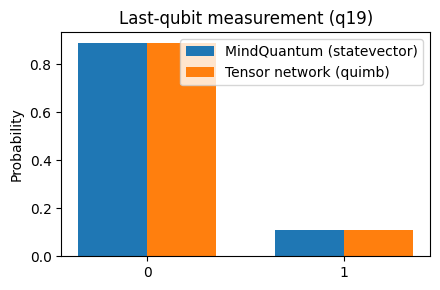

In [6]:
import matplotlib.pyplot as plt

labels = ['0', '1']
x = np.arange(2)
width = 0.35

plt.figure(figsize=(4.5, 3.0))
plt.bar(x - width / 2, probs_sv, width, label='MindQuantum (statevector)')
plt.bar(x + width / 2, probs_tn, width, label='Tensor network (quimb)')
plt.xticks(x, labels)
plt.ylabel('Probability')
plt.title(f'Last-qubit measurement (q{last})')
plt.legend()
plt.tight_layout()
plt.show()


## 5) Optional visualization (tensor network + contraction tree)

Run the next cell to render:

- the tensor network graph
- the contraction tree (ring and tent layouts)

(They can be slow for larger circuits.)

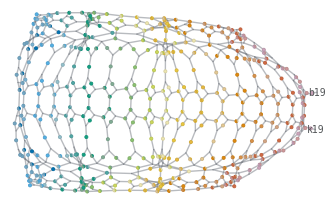

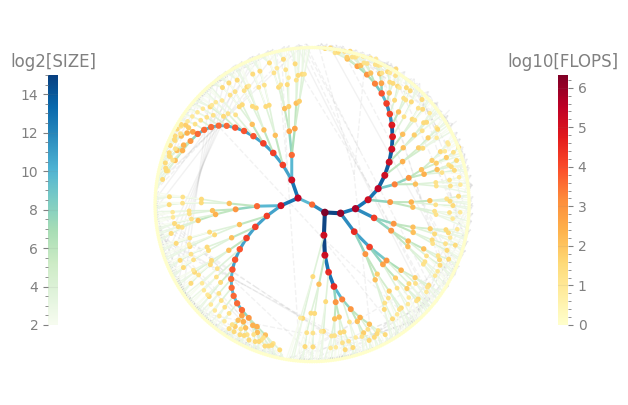

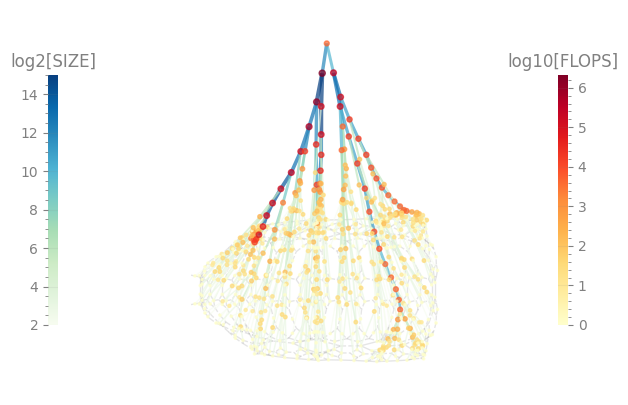

(<Figure size 500x500 with 3 Axes>, <Axes: >)

In [7]:
tn_rho_last.graph(
    initial_layout='kamada_kawai',
    iterations=50,
    color=tn_circ.psi.site_tags,
    legend=False,
    figsize=(4, 4),
)

tree.plot_ring(node_scale=1 / 3, edge_scale=2 / 3)
tree.plot_tent(node_scale=1 / 3, edge_scale=2 / 3)

## Summary

- The demo shows how to route a MindQuantum circuit through **OpenQASM2** into **quimb**.
- We then contract a tensor network (with help from **cotengra**) to obtain the one-qubit reduced density matrix.
- The probabilities match the MindQuantum statevector simulator (up to floating-point tolerance).

Next steps you might explore:

- increase `N_QUBITS` and see where statevector simulation becomes infeasible
- experiment with circuit structures that generate less/more entanglement
- install `optuna` and set `optlib='optuna'` for more powerful hyper-optimization
- try different cotengra methods and slicing options